# 03 — Visualisation des données énergétiques

Les graphiques sont construits à partir de la table préparée. Ils servent à comprendre la tendance temporelle, le profil journalier, les différences entre jours de la semaine et week-end, la distribution des puissances et la couverture des mesures.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "sinert_features.csv"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TIMESTAMP = "timestamp"
ENERGY = "EM_VIRTUAL kWh (kWh) [ABS]"
ACTIVE_POWER = "EM_VIRTUAL kW sys (kW) [AVG]"
APPARENT_POWER = "EM_VIRTUAL kVA sys (kVA) [AVG]"

df = pd.read_csv(PROCESSED_PATH, parse_dates=[TIMESTAMP])
df = df.sort_values(TIMESTAMP).reset_index(drop=True)
df["hour"] = df[TIMESTAMP].dt.hour + df[TIMESTAMP].dt.minute / 60
df["day_of_week"] = df[TIMESTAMP].dt.day_of_week
print(f"Lignes visualisables : {len(df):,}")
print(f"Période : {df[TIMESTAMP].min()} → {df[TIMESTAMP].max()}")
print(f"Puissance active moyenne : {df[ACTIVE_POWER].mean():.2f} kW")


Lignes visualisables : 127,184
Période : 2022-07-05 00:00:00 → 2026-02-28 23:45:00
Puissance active moyenne : 60.45 kW


## 1. Évolution quotidienne de l'énergie

La colonne `kWh [ABS]` est un compteur cumulatif. On utilise donc ses différences uniquement entre deux mesures consécutives de 15 minutes et on ignore les ruptures de couverture.

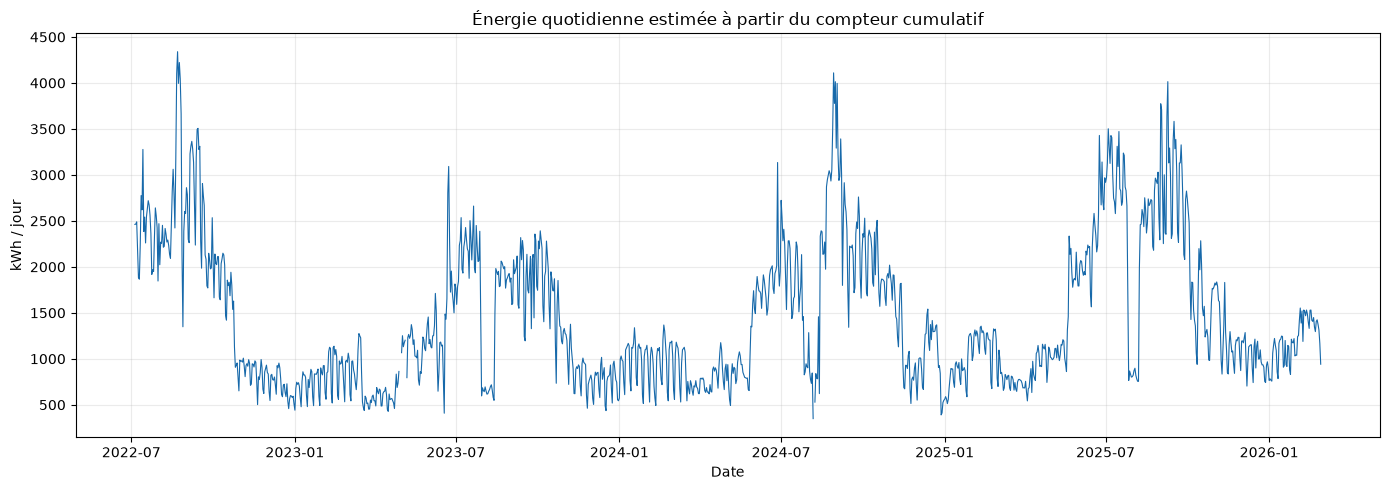

Jours avec une estimation : 1,331


In [2]:
indexed = df.set_index(TIMESTAMP)
energy_delta = indexed[ENERGY].diff()
time_delta = indexed.index.to_series().diff()
energy_delta = energy_delta.where(
    time_delta.eq(pd.Timedelta(minutes=15)) & energy_delta.ge(0)
)
daily_energy = energy_delta.resample("D").sum(min_count=1)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_energy.index, daily_energy, linewidth=0.8, color="#1769aa")
ax.set_title("Énergie quotidienne estimée à partir du compteur cumulatif")
ax.set_xlabel("Date")
ax.set_ylabel("kWh / jour")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "01_energie_quotidienne.png", dpi=150)
plt.show()
plt.close(fig)
print(f"Jours avec une estimation : {daily_energy.notna().sum():,}")


## 2. Profil horaire moyen de la puissance

Ce graphique montre les heures auxquelles la puissance active et apparente sont généralement les plus élevées.

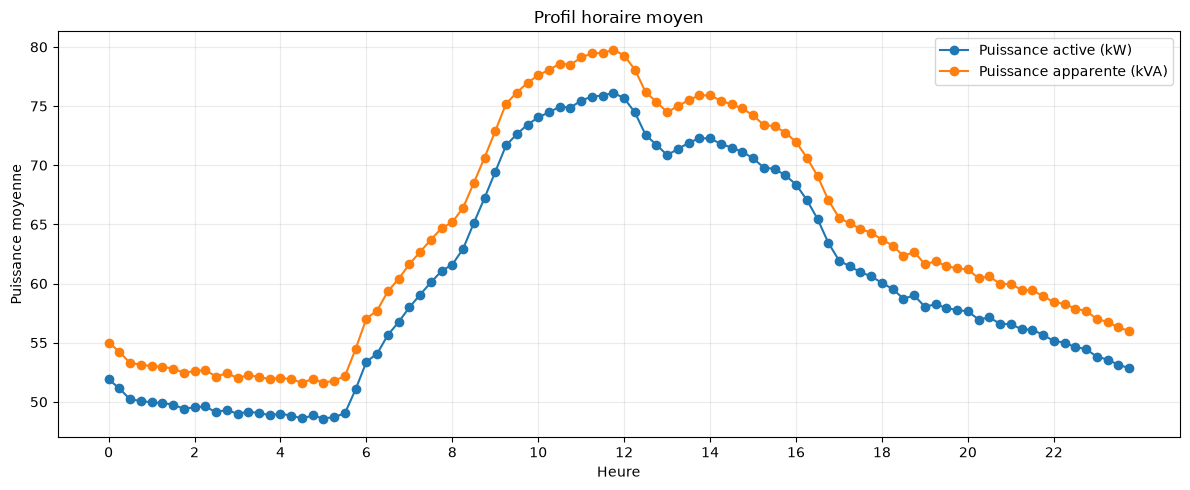

In [3]:
hourly_profile = df.groupby("hour")[[ACTIVE_POWER, APPARENT_POWER]].mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hourly_profile.index, hourly_profile[ACTIVE_POWER], marker="o", label="Puissance active (kW)")
ax.plot(hourly_profile.index, hourly_profile[APPARENT_POWER], marker="o", label="Puissance apparente (kVA)")
ax.set_title("Profil horaire moyen")
ax.set_xlabel("Heure")
ax.set_ylabel("Puissance moyenne")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "02_profil_horaire.png", dpi=150)
plt.show()
plt.close(fig)


## 3. Comparaison jours de la semaine / heures

La carte de chaleur permet de repérer rapidement les périodes de forte demande selon le jour et l'heure.

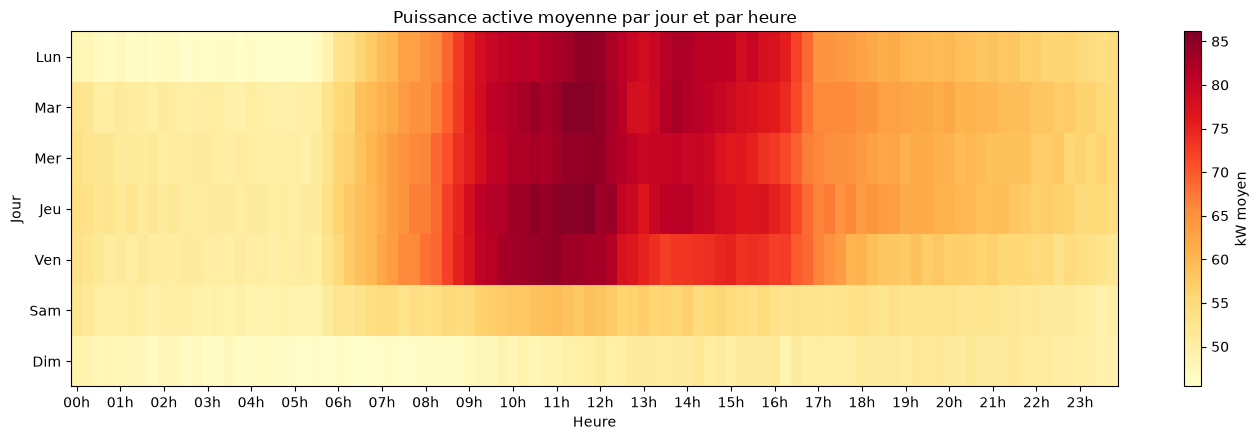

In [4]:
weekday_hour = df.pivot_table(
    index="day_of_week",
    columns="hour",
    values=ACTIVE_POWER,
    aggfunc="mean",
)
fig, ax = plt.subplots(figsize=(14, 4.5))
image = ax.imshow(weekday_hour, aspect="auto", cmap="YlOrRd")
ax.set_title("Puissance active moyenne par jour et par heure")
ax.set_xlabel("Heure")
ax.set_ylabel("Jour")
ax.set_xticks(range(0, len(weekday_hour.columns), 4), [f"{int(hour):02d}h" for hour in weekday_hour.columns[::4]])
ax.set_yticks(range(7), ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"])
fig.colorbar(image, ax=ax, label="kW moyen")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "03_carte_chaleur_semaine.png", dpi=150)
plt.show()
plt.close(fig)


## 4. Distribution des puissances et facteur de puissance

Les distributions permettent de détecter une asymétrie, des valeurs extrêmes ou une différence importante entre kW et kVA.

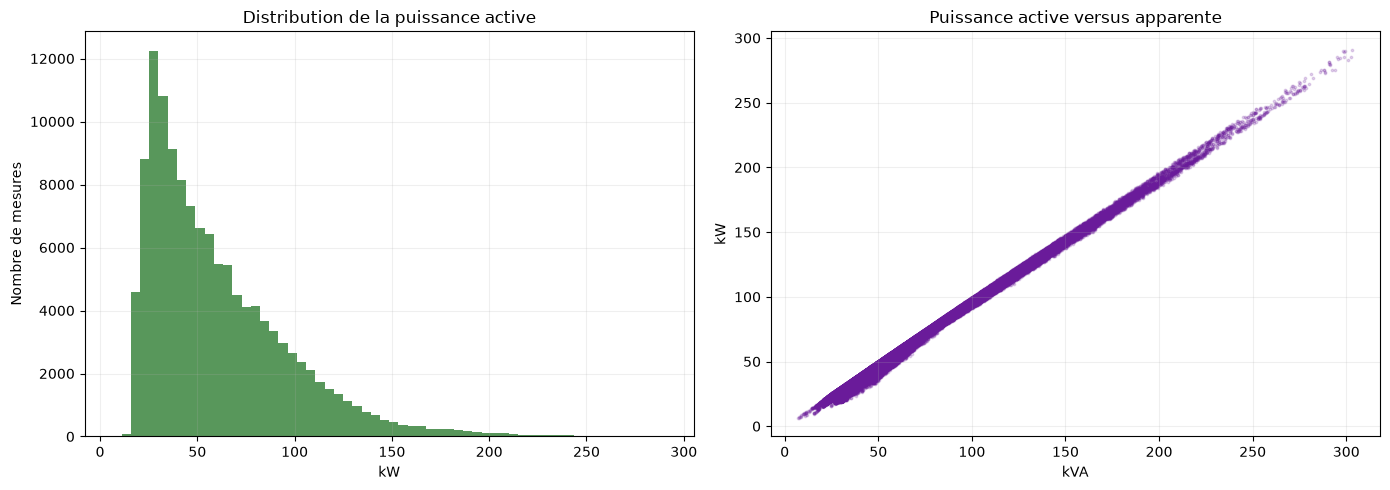

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df[ACTIVE_POWER].dropna(), bins=60, color="#2e7d32", alpha=0.8)
axes[0].set_title("Distribution de la puissance active")
axes[0].set_xlabel("kW")
axes[0].set_ylabel("Nombre de mesures")
axes[0].grid(alpha=0.2)
axes[1].scatter(df[APPARENT_POWER], df[ACTIVE_POWER], s=3, alpha=0.18, color="#6a1b9a")
axes[1].set_title("Puissance active versus apparente")
axes[1].set_xlabel("kVA")
axes[1].set_ylabel("kW")
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "04_distribution_puissance.png", dpi=150)
plt.show()
plt.close(fig)


## 5. Couverture temporelle

On vérifie ici le nombre de mesures utilisables par jour afin de rendre visibles les périodes absentes après le nettoyage.

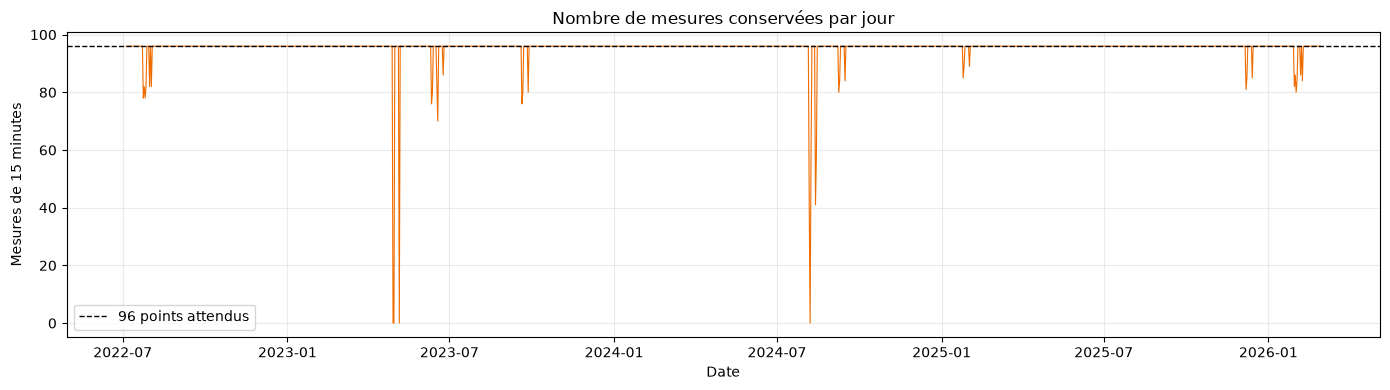

Jours complets : 1,298
Jours incomplets : 37


In [6]:
daily_counts = indexed.resample("D").size()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily_counts.index, daily_counts, linewidth=0.8, color="#ef6c00")
ax.axhline(96, color="black", linestyle="--", linewidth=1, label="96 points attendus")
ax.set_title("Nombre de mesures conservées par jour")
ax.set_xlabel("Date")
ax.set_ylabel("Mesures de 15 minutes")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "05_couverture_temporelle.png", dpi=150)
plt.show()
plt.close(fig)
print(f"Jours complets : {(daily_counts == 96).sum():,}")
print(f"Jours incomplets : {(daily_counts < 96).sum():,}")
